In [1]:
# INICIALIZAÇÃO DAS BIBLIOTECAS
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from scipy.optimize import curve_fit

def set_rho(ff, rho_tot):
    '''
    Proton Density.
    rho_tot = total proton density
    '''
    rho_fat = ff*rho_tot
    rho_water = rho_tot - rho_fat
    return(rho_fat, rho_water)

def discrete_timeseries(n_echoes):
    '''
    This function calculates the GRE IP-OP signal from human liver, for any number of TEs,
    considering a low flip angle (Taylor approx. around zero) and 3T (TEs adjusted for 3T).
    This is based on studies by Hamilton and Yokoo.
    parameters: n_echoes     -> integer >0, number of equally spaced echoes
    returns:    echo_times
     '''
    
    # TE acquisition times for n echoes
    echo_times = np.linspace(0.0011515, 0.0011515*n_echoes, n_echoes, endpoint=True)
    return(echo_times)


def gen_GRE(echo_times, rho_fat, rho_water):
    '''
    This function calculates the GRE IP-OP signal from human liver, for any number of TEs,
    considering a low flip angle (Taylor approx. around zero) and 3T (TEs adjusted for 3T).
    This is based on studies by Hamilton and Yokoo.
    parameters: echo times -> array with TEs
                rho_fat    -> float >0, fat proton density
                rho_water  -> float >0, water proton density
    returns:    Sabs (absolute signal intensity) (equivalent to ydata)
    '''
    
    # rho_fat is a general variable that multiplies intrinsic fat constants (Hamilton)
    rho = np.array([rho_fat*0.047, rho_fat*0.039, rho_fat*0.006, 
                    rho_fat*0.12, rho_fat*0.7, rho_fat*0.088, rho_water])
    
    # standard, individual T2* values
    t2star = np.array([0.030, 0.040, 0.051, 0.052, 0.062, 0.083, 0.023] )
    
    # frequency in parts per million for each moiety
    freq_ppm = np.array([5.3, 4.2, 2.75, 2.1, 1.3, 0.9, 4.7])

    freq = np.zeros(len(freq_ppm))
    magField = np.array(3.0)      # magnetic field, Tesla (if change, remember to change echo spacing)
    hydroGyro = np.array(42.57e6) # Hydrogen gyromagnetic ratio, Hz/T
    
    for n, fppm in enumerate(freq_ppm):
        freq[n] = fppm*magField*hydroGyro/1e6
    
    # calculate the complex signal for each moiety    
    S = (len(freq_ppm),len(echo_times))
    S = np.zeros(S,dtype='complex')
    
    for n, moieties in enumerate(freq_ppm):
        for t,TE in enumerate(echo_times):
            S[n,t] = rho[n]*np.exp(-TE/t2star[n])*np.exp(2.0*np.pi*1j*freq[n]*TE)         
    
    # obtain sum & absolute value
    Sabs= (len(echo_times))
    Sabs=np.zeros(Sabs,dtype='complex')
    
    Sabs = np.sum(S, axis=0)
    Sabs = np.absolute(Sabs)
    return(Sabs)


def continuous_timeseries(endpoint=0.01):
    return(np.linspace(0, endpoint, 1000, endpoint=True))

def calc_fatfrac(fitted_parameters):
    ff =  fitted_parameters[0] / (fitted_parameters[0] + fitted_parameters[1])
    return(ff)

### variando gordura

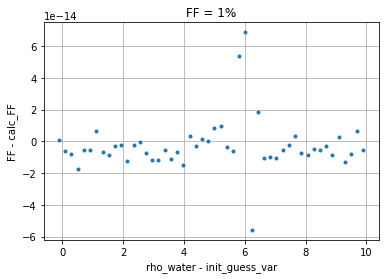

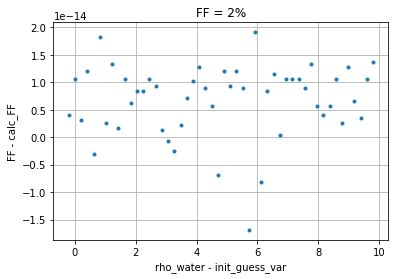

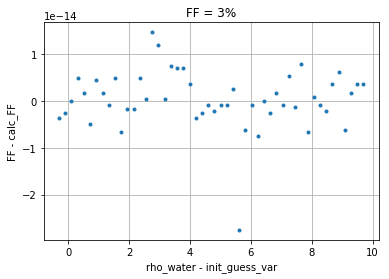

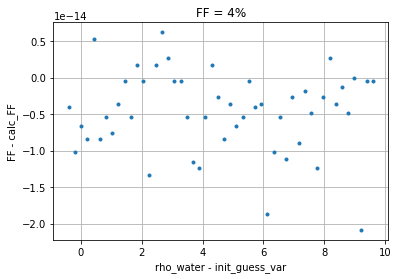

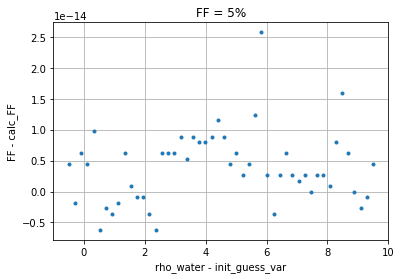

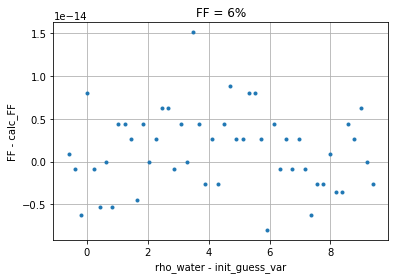

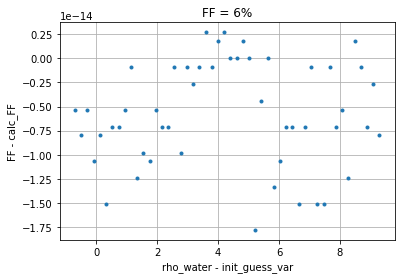

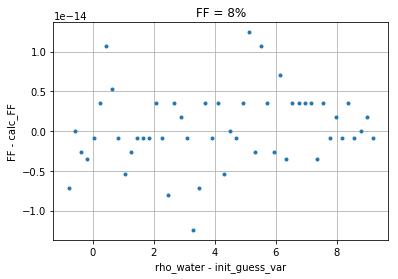

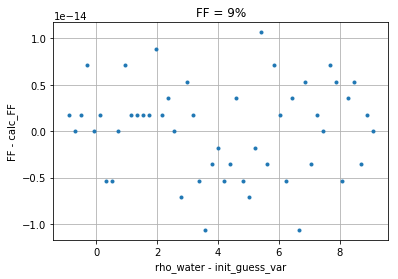

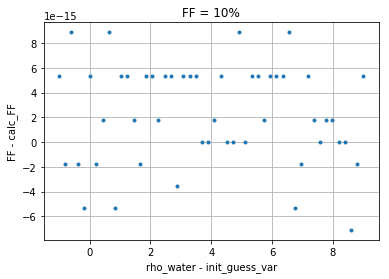

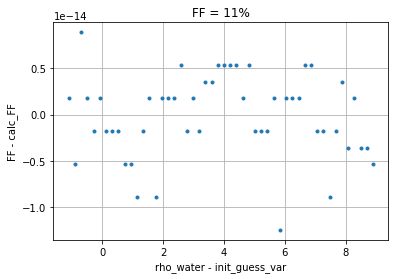

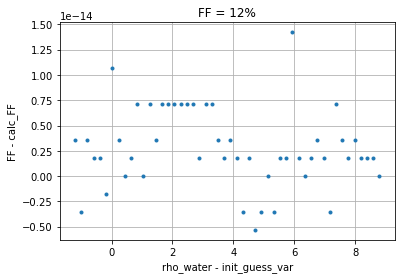

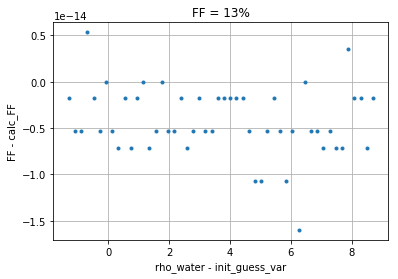

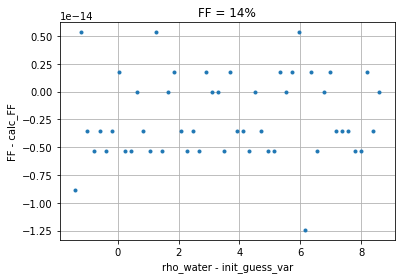

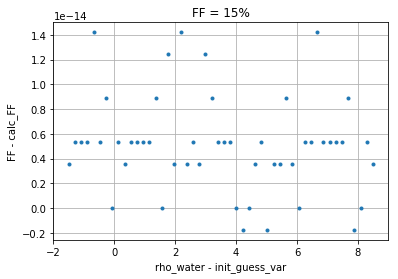

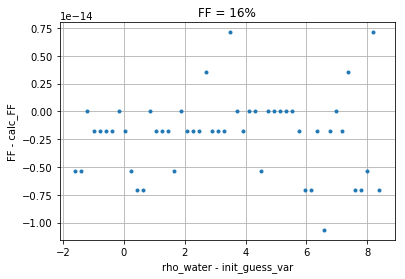

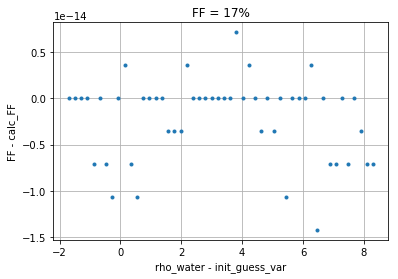

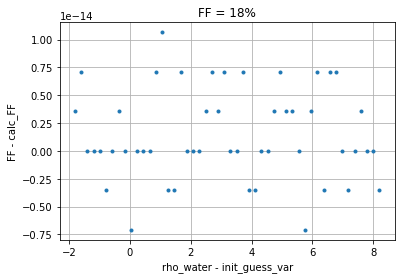

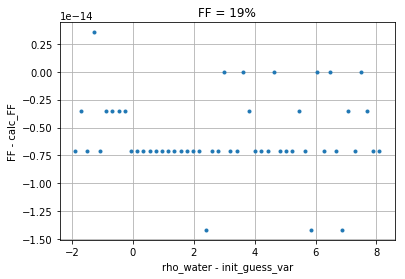

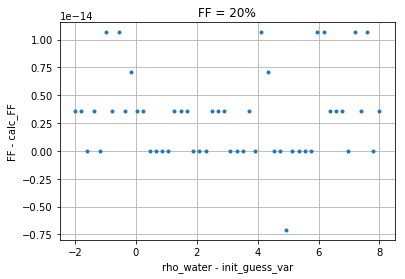

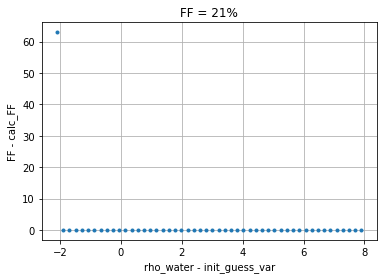

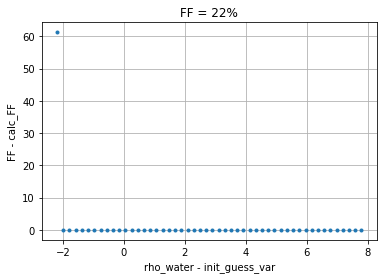

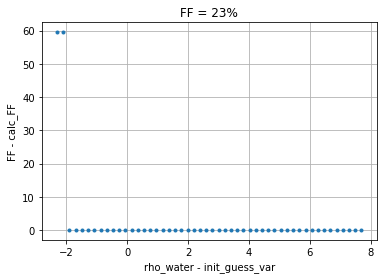

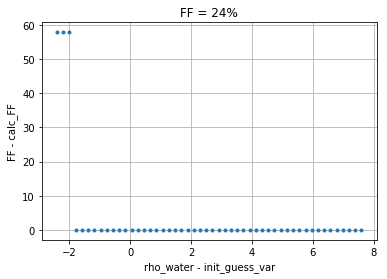

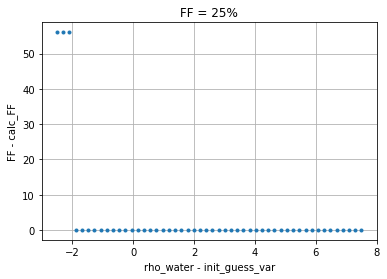

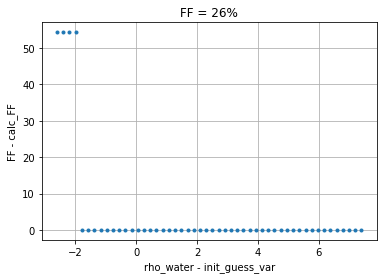

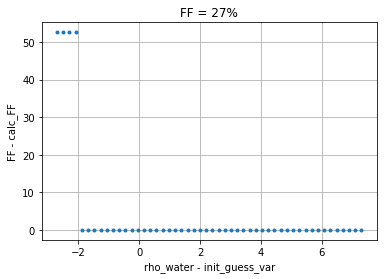

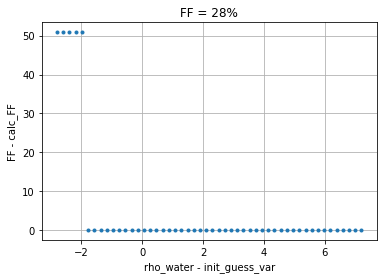

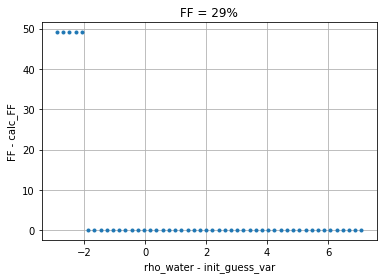

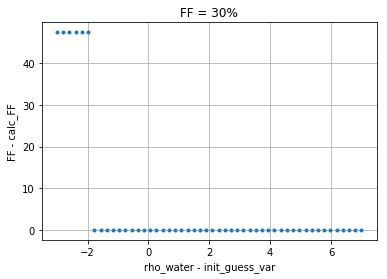

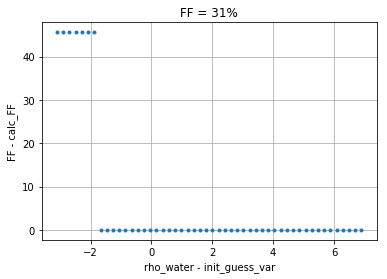

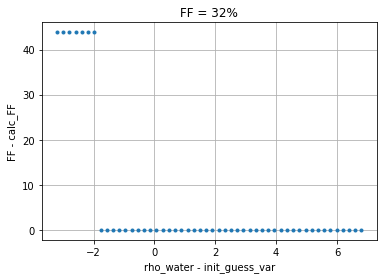

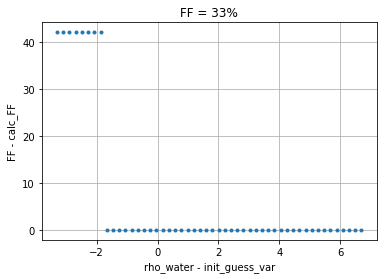

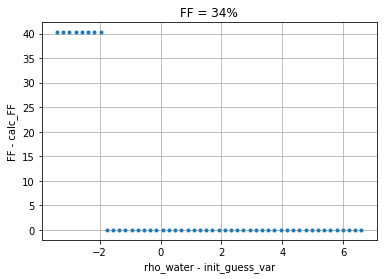

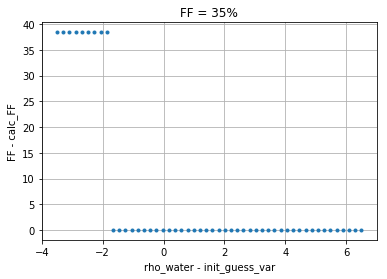

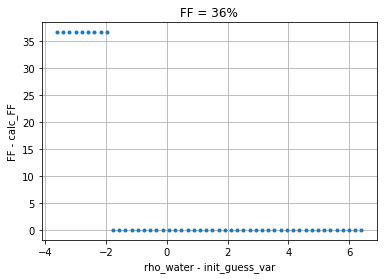

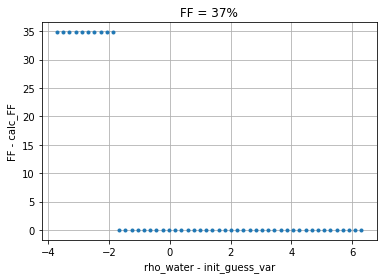

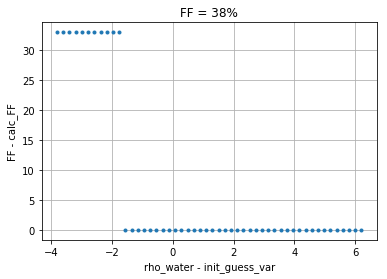

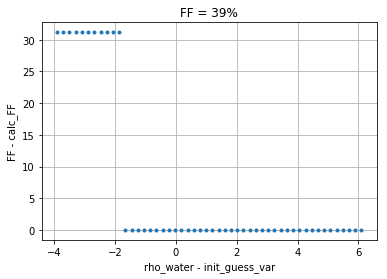

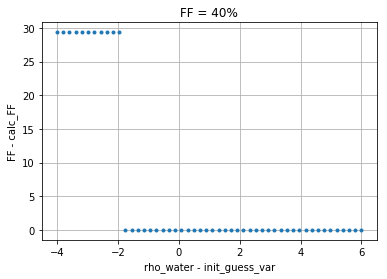

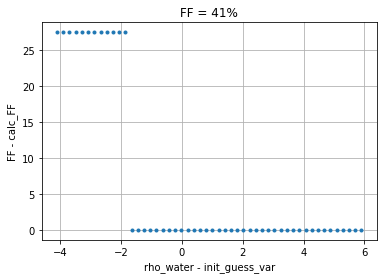

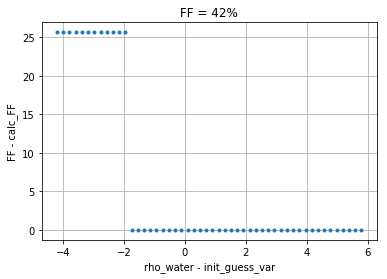

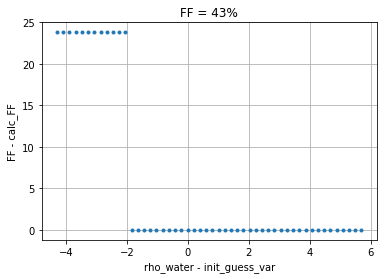

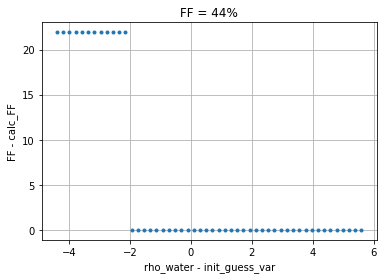

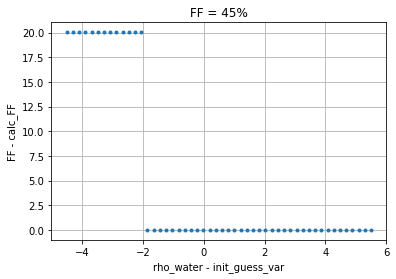

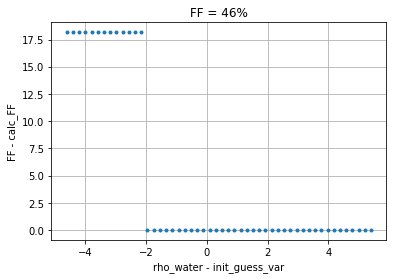

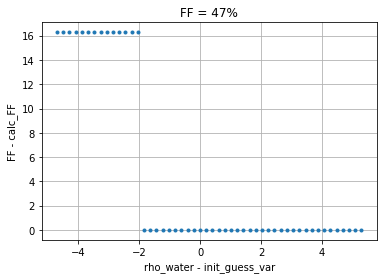

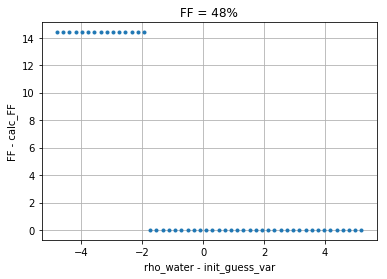

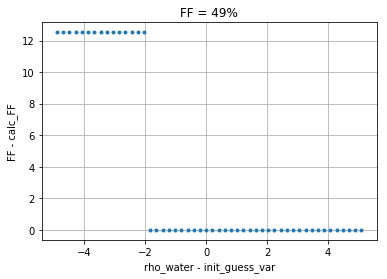

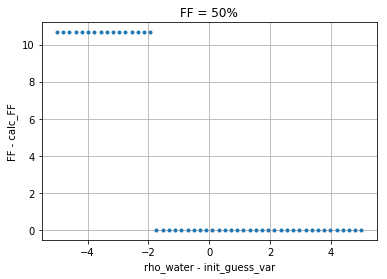

In [41]:
x = continuous_timeseries()  # plotar função contínua
ff = np.linspace(0.01, 0.50) # fat fraction
rho_tot = 10                 # rho_water + rho_fat
init_guess_var = np.linspace(0, rho_tot) # erro para valores iniciais

for fat in ff:
    fitted10 = []
    rho_fat, rho_water = set_rho(fat, rho_tot)
    xdata = discrete_timeseries(7)
    ydata = gen_GRE(xdata, rho_fat, rho_water)
    
    for rhof_init in init_guess_var:
        p0 = [rhof_init, rho_water] # FAT + init_guess_var
        fitted_par, pcov = curve_fit(gen_GRE, xdata, ydata, p0=p0) 
        fitted10.append(100*calc_fatfrac(fitted_par))
        
    ref10 = np.zeros(np.size(fitted10))+100*fat # original FF
    
    #print('rho_fat = %.3f' % rho_fat)
    #print('rho_water = %.3f' % rho_water)
    #print('FF calc = %.3f' % calc_fatfrac(fitted_par))
    #tot = rho_water+rho_fat
    #print('rho_tot = %.3f' % tot)
    
    fig, ax = plt.subplots()
    ax.plot(rho_water-init_guess_var, fitted10-ref10, '.')
    #ax.plot(init_guess_var, ref10, '.')
    #ax.plot(rho_water-init_guess_var, ref10-calc_fatfrac(fitted_par), '.')
    
    i = fat*100
    ax.set_title('FF = %d%%' % i)
    ax.set_xlabel('rho_water - init_guess_var')
    ax.set_ylabel('FF - calc_FF')
    #ax.legend(loc='best')
    ax.autoscale(enable=True)
    ax.ticklabel_format(useOffset=False)
    plt.grid(True)
    plt.show()

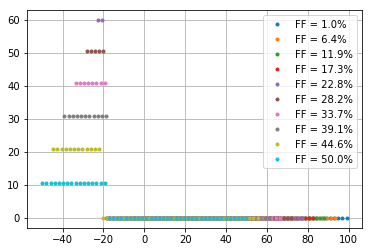

In [56]:
x = continuous_timeseries()  # plotar função contínua
ff = np.linspace(0.01, 0.50, num=10) # fat fraction
rho_tot = 100                 # rho_water + rho_fat
init_guess_var = np.linspace(0, rho_tot) # erro para valores iniciais

for fat in ff:
    fitted10 = []
    rho_fat, rho_water = set_rho(fat, rho_tot)
    xdata = discrete_timeseries(7)
    ydata = gen_GRE(xdata, rho_fat, rho_water)
    
    for rhof_init in init_guess_var:
        p0 = [rhof_init, rho_water] # FAT + init_guess_var
        fitted_par, pcov = curve_fit(gen_GRE, xdata, ydata, p0=p0) 
        fitted10.append(100*calc_fatfrac(fitted_par))
        
    ref10 = np.zeros(np.size(fitted10))+100*fat # original FF
    
    #print('rho_fat = %.3f' % rho_fat)
    #print('rho_water = %.3f' % rho_water)
    #print('FF calc = %.3f' % calc_fatfrac(fitted_par))
    #tot = rho_water+rho_fat
    #print('rho_tot = %.3f' % tot)
    
    #fig, ax = plt.subplots()
    fat_label = 100*fat
    plt.plot(rho_water-init_guess_var, fitted10-ref10, '.', label='FF = %.1f%%' % fat_label)
    #ax.plot(init_guess_var, ref10, '.')
    #ax.plot(rho_water-init_guess_var, ref10-calc_fatfrac(fitted_par), '.')
    
#i = fat*100
#ax.set_title('FF = %d%%' % i)
#ax.set_xlabel('rho_water - init_guess_var')
#ax.set_ylabel('FF - calc_FF')
plt.legend(loc='best')
plt.autoscale(enable=True)
plt.ticklabel_format(useOffset=False)
plt.grid(True)
#plt.xlim(-40,-20)
plt.show()

### variando água, gráficos separados

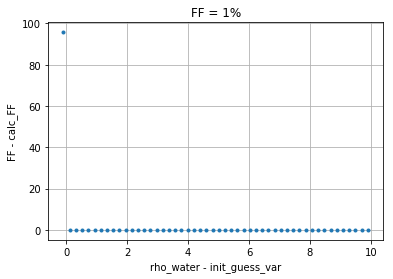

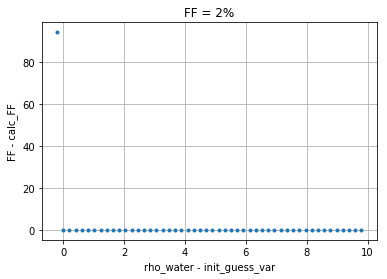

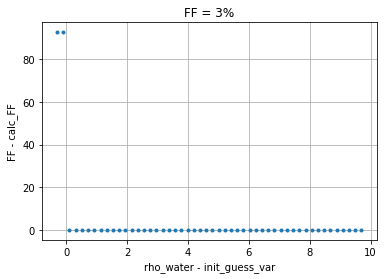

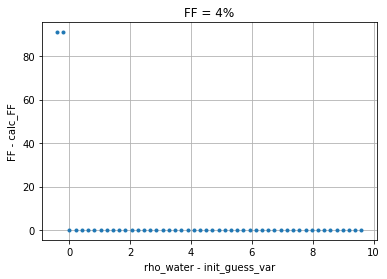

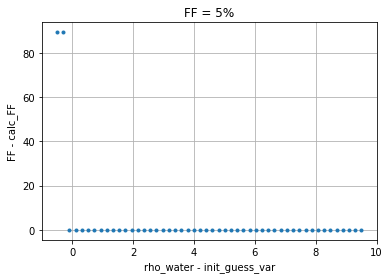

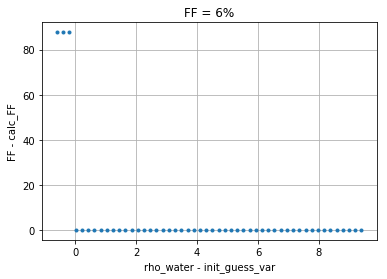

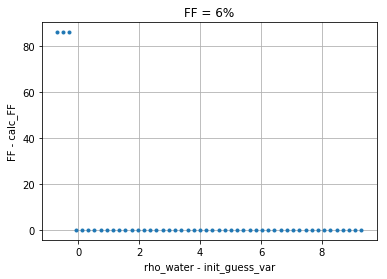

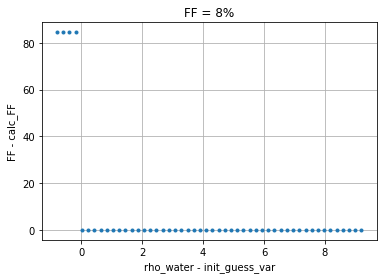

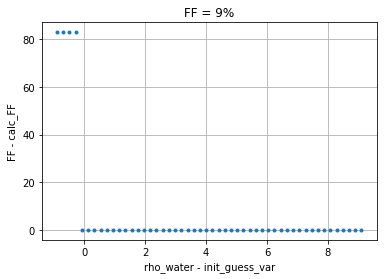

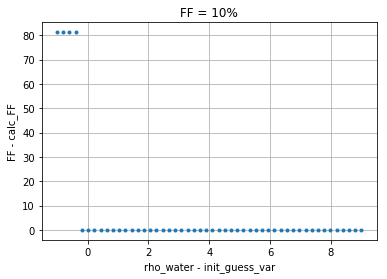

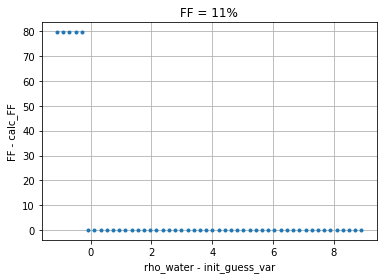

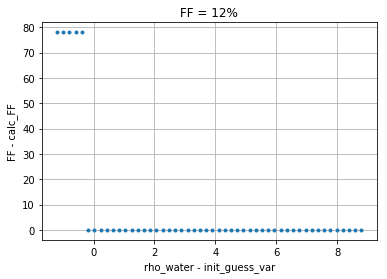

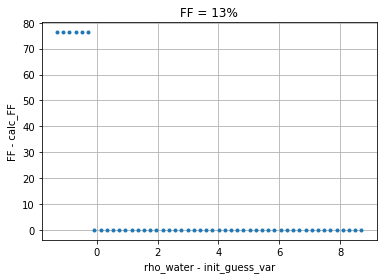

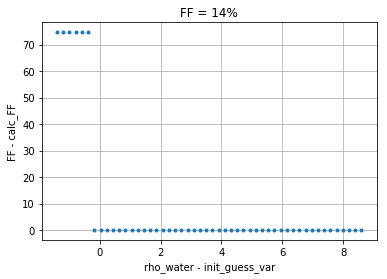

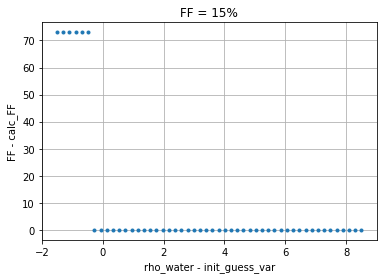

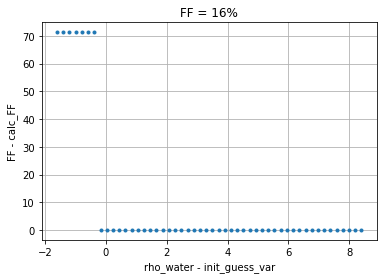

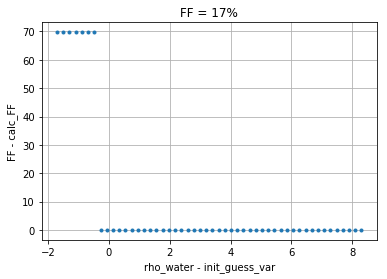

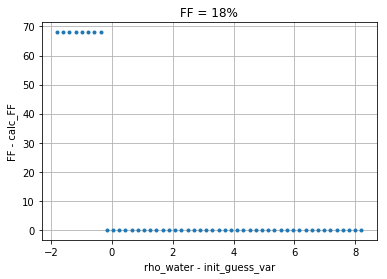

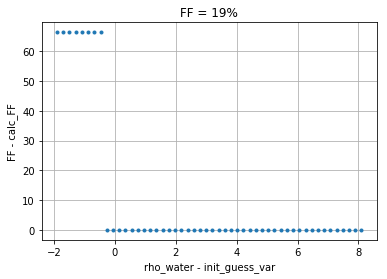

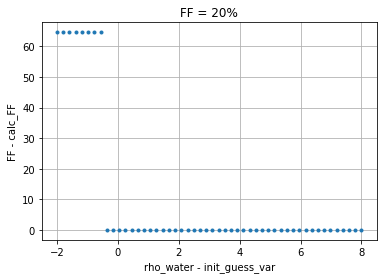

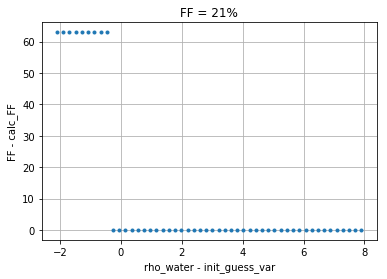

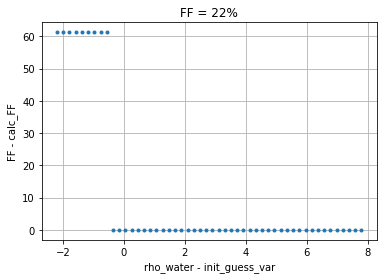

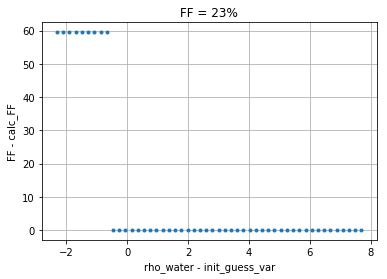

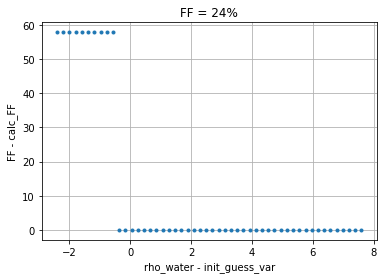

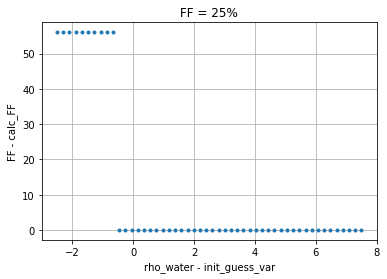

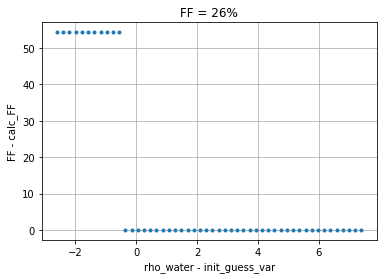

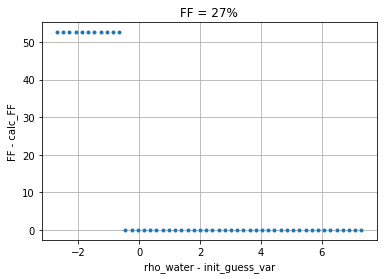

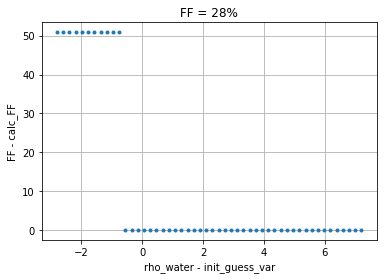

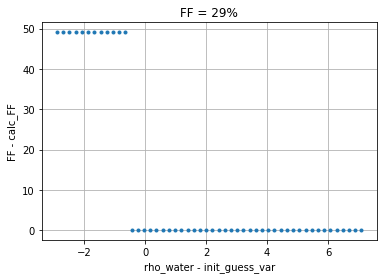

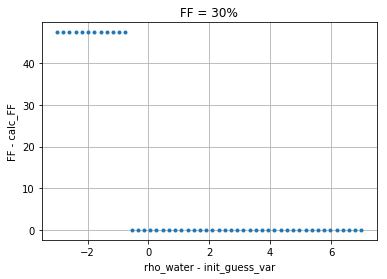

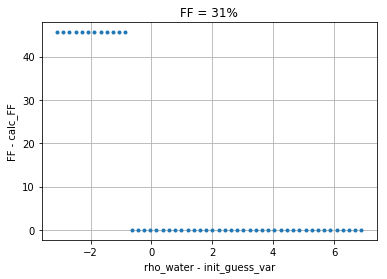

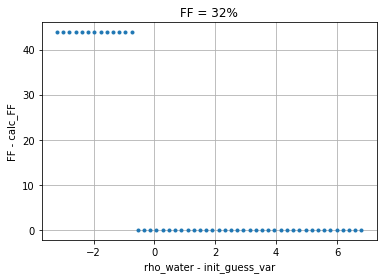

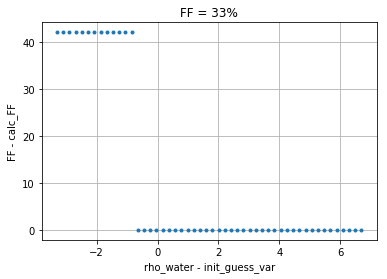

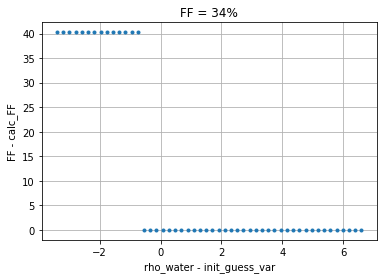

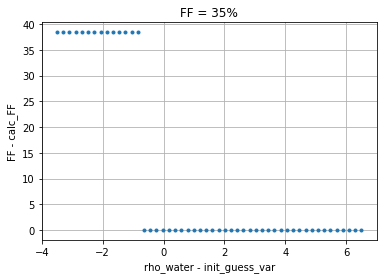

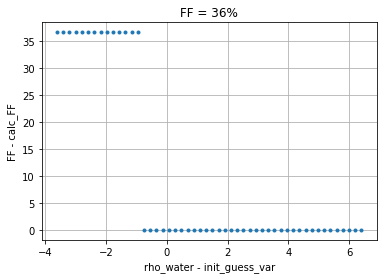

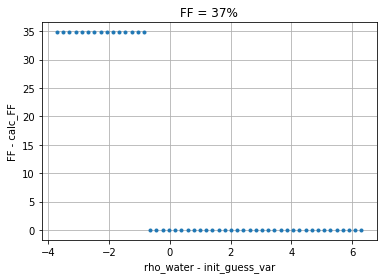

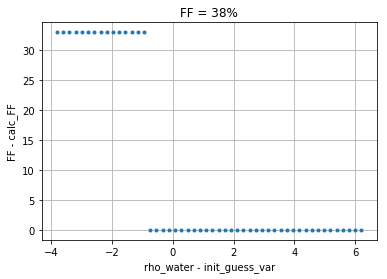

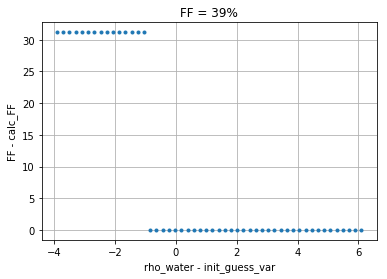

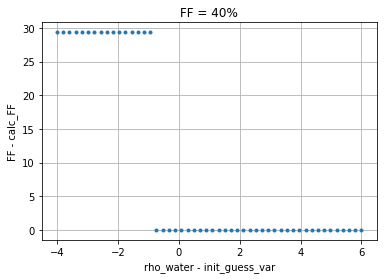

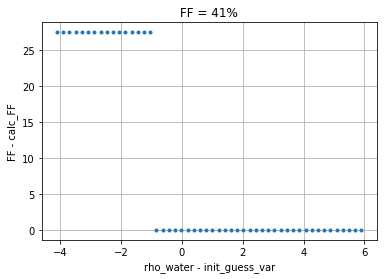

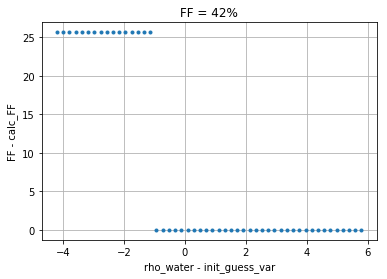

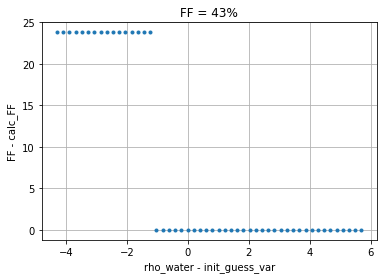

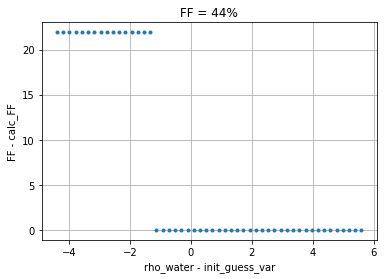

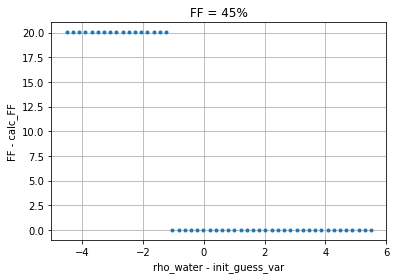

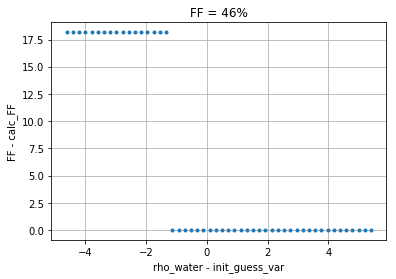

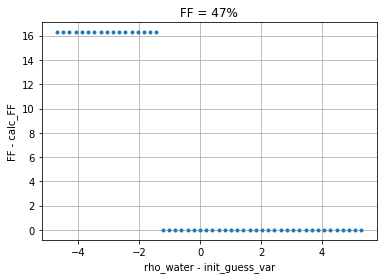

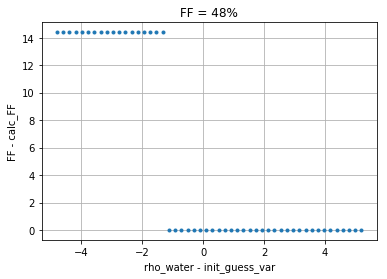

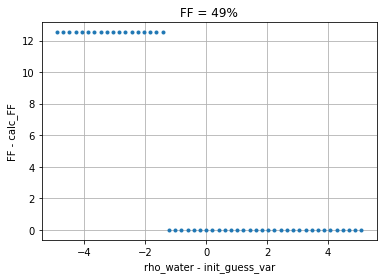

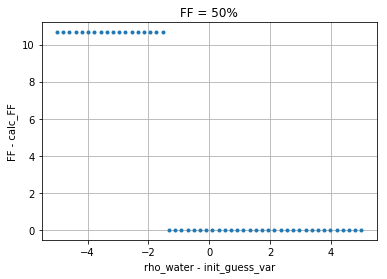

In [11]:
x = continuous_timeseries()  # plotar função contínua
ff = np.linspace(0.01, 0.50) # fat fraction
rho_tot = 10                 # rho_water + rho_fat
init_guess_var = np.linspace(0, rho_tot) # erro para valores iniciais

for fat in ff:
    fitted10 = []
    rho_fat, rho_water = set_rho(fat, rho_tot)
    xdata = discrete_timeseries(7)
    ydata = gen_GRE(xdata, rho_fat, rho_water)
    
    for rhow_init in init_guess_var:
        p0 = [rho_fat, rhow_init] # fat + variable water
        fitted_par, pcov = curve_fit(gen_GRE, xdata, ydata, p0=p0) 
        fitted10.append(100*calc_fatfrac(fitted_par))
        
    ref10 = np.zeros(np.size(fitted10))+100*fat # original FF
    
    #print('rho_fat = %.3f' % rho_fat)
    #print('rho_water = %.3f' % rho_water)
    #print('FF calc = %.3f' % calc_fatfrac(fitted_par))
    #tot = rho_water+rho_fat
    #print('rho_tot = %.3f' % tot)
    
    fig, ax = plt.subplots()
    ax.plot(init_guess_var-rho_fat, fitted10-ref10, '.')
    #ax.plot(init_guess_var, ref10, '.')
    #ax.plot(rho_water-init_guess_var, ref10-calc_fatfrac(fitted_par), '.')
    
    i = fat*100
    ax.set_title('FF = %d%%' % i)
    ax.set_xlabel('rho_water - init_guess_var')
    ax.set_ylabel('FF - calc_FF')
    #ax.legend(loc='best')
    ax.autoscale(enable=True)
    ax.ticklabel_format(useOffset=False)
    plt.grid(True)
    plt.show()

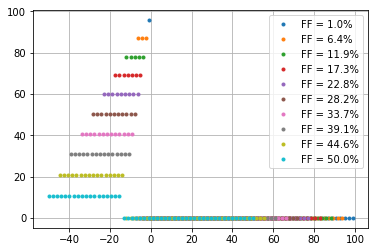

In [44]:
x = continuous_timeseries()  # plotar função contínua
ff = np.linspace(0.01, 0.50, num=10) # fat fraction
rho_tot = 100                 # rho_water + rho_fat
init_guess_var = np.linspace(0, rho_tot) # erro para valores iniciais

for fat in ff:
    fitted10 = []
    rho_fat, rho_water = set_rho(fat, rho_tot)
    xdata = discrete_timeseries(7)
    ydata = gen_GRE(xdata, rho_fat, rho_water)
    
    for rhow_init in init_guess_var:
        p0 = [rho_fat, rhow_init] # fat + variable water
        fitted_par, pcov = curve_fit(gen_GRE, xdata, ydata, p0=p0) 
        fitted10.append(100*calc_fatfrac(fitted_par))
        
    ref10 = np.zeros(np.size(fitted10))+100*fat # original FF
    
    #fig, ax = plt.subplots()
    fat_label = 100*fat
    plt.plot(init_guess_var-rho_fat, fitted10-ref10, '.', label='FF = %.1f%%' % fat_label)
    #ax.plot(init_guess_var, ref10, '.')
    #ax.plot(rho_water-init_guess_var, ref10-calc_fatfrac(fitted_par), '.')
    
#i = fat*100
#ax.set_title('FF = %d%%' % i)
#ax.set_xlabel('rho_water - init_guess_var')
#ax.set_ylabel('FF - calc_FF')
plt.legend(loc='best')
plt.autoscale(enable=True)
plt.ticklabel_format(useOffset=False)
plt.grid(True)
plt.show()